In [1]:
import requests
from bs4 import BeautifulSoup

url_happybooks = "https://happybooks.com.co/"

respuesta_happybooks = requests.get(
    url_happybooks,
    timeout=20,
    headers={"User-Agent": "Mozilla/5.0"}
)

print("Código HTTP:", respuesta_happybooks.status_code)
print("URL final:", respuesta_happybooks.url)
print("Tamaño del HTML:", len(respuesta_happybooks.text))

soup_happybooks = BeautifulSoup(
    respuesta_happybooks.text,
    "html.parser"
)

print(
    "Título:",
    soup_happybooks.title.get_text(strip=True)
    if soup_happybooks.title else "No encontrado"
)

print("Cantidad de enlaces:", len(soup_happybooks.find_all("a")))

Código HTTP: 200
URL final: https://happybooks.com.co/
Tamaño del HTML: 826467
Título: Librería Happy Books: Compra libros desde la comodidad de casa
Cantidad de enlaces: 514


In [2]:
# Buscar posibles tarjetas de productos en el HTML
selectores = [
    ".product-item",
    ".product",
    ".product-card",
    ".grid__item",
    "li.product"
]

for selector in selectores:
    resultados = soup_happybooks.select(selector)
    print(f"{selector}: {len(resultados)} elementos")

.product-item: 0 elementos
.product: 0 elementos
.product-card: 0 elementos
.grid__item: 0 elementos
li.product: 0 elementos


In [3]:
texto_pagina = soup_happybooks.get_text(" ", strip=True)

print("Apariciones de '$':", texto_pagina.count("$"))
print("\nPrimeros 1500 caracteres del texto:\n")
print(texto_pagina[:1500])

Apariciones de '$': 437

Primeros 1500 caracteres del texto:

Librería Happy Books: Compra libros desde la comodidad de casa HAPPY BOOKS 🚨 Libros en Medellín Mismo Día. Ver más 🫶🏻 Amigos Happy Books Ver más Menú Buscar 0 / $0 Categorías Ofertas Novedades Amigos Happy Books B2B Medellín Mismo Día Blog Rastrea tu pedido Ofertas -25% James Clear Libro Hábitos Atómicos $79,000 $59,250 Ahorras $19,750 Tapa rústica Hoy en Medellín · gratis desde $150.000 -25% Rojas Estapé, Marian Libro Cómo hacer que te pasen cosas buenas $65,000 $48,750 Ahorras $16,250 Tapa rústica Hoy en Medellín · gratis desde $150.000 -30% Tolle, Eckhart Libro El Poder Del Ahora $69,000 $48,300 Ahorras $20,700 Tapa rústica Hoy en Medellín · gratis desde $150.000 -30% Sharma, Robin Libro El Club De Las 5 De La Mañana $69,000 $48,300 Ahorras $20,700 Tapa rústica Hoy en Medellín · gratis desde $150.000 -30% Walsch, Neale Donald Libro Conversaciones Con Dios I $52,000 $36,400 Ahorras $15,600 Tapa rústica de bolsillo Hoy en M

In [4]:
# Buscar un título de libro en el HTML
texto_buscado = "Hábitos Atómicos"

elementos = soup_happybooks.find_all(
    string=lambda texto: texto and texto_buscado.lower() in texto.lower()
)

print("Coincidencias encontradas:", len(elementos))

for elemento in elementos[:3]:
    print("\n--- ELEMENTO ENCONTRADO ---")

    padre = elemento.parent

    print("Etiqueta:", padre.name)
    print("Clases:", padre.get("class"))
    print("Texto:", padre.get_text(" ", strip=True)[:300])

    print("\nElemento contenedor:")
    print(str(padre.parent)[:1200])

Coincidencias encontradas: 2

--- ELEMENTO ENCONTRADO ---
Etiqueta: a
Clases: None
Texto: Libro Hábitos Atómicos

Elemento contenedor:
<h3 class="hb-card__title">
<a data-pr-href="" href="/products/9789584277954-habitos-atomicos-james-clear">Libro Hábitos Atómicos</a>
</h3>

--- ELEMENTO ENCONTRADO ---
Etiqueta: a
Clases: None
Texto: Hábitos Atómicos. Edición Especial Tapa Dura

Elemento contenedor:
<h3 class="hb-card__title">
<a data-pr-href="" href="/products/libro-habitos-atomicos-edicion-especial-tapa-dura-clear-james-9786287578364">Hábitos Atómicos. Edición Especial Tapa Dura</a>
</h3>


In [5]:
# Buscar el título y examinar sus contenedores
titulo = soup_happybooks.select_one("h3.hb-card__title")

if titulo:
    contenedor = titulo

    for nivel in range(1, 6):
        if contenedor.parent:
            contenedor = contenedor.parent

        print(f"\n--- NIVEL {nivel} ---")
        print("Etiqueta:", contenedor.name)
        print("Clases:", contenedor.get("class"))
        print("Texto:", contenedor.get_text(" ", strip=True)[:500])
        print("HTML:", str(contenedor)[:1500])
else:
    print("No se encontró ningún título de producto.")


--- NIVEL 1 ---
Etiqueta: div
Clases: ['hb-card__content']
Texto: James Clear Libro Hábitos Atómicos $79,000 $59,250 Ahorras $19,750 Tapa rústica Hoy en Medellín · gratis desde $150.000
HTML: <div class="hb-card__content"><div class="hb-card__author">
<a href="/collections/vendors?q=James%20Clear">James Clear</a>
</div><h3 class="hb-card__title">
<a data-pr-href="" href="/products/9789584277954-habitos-atomicos-james-clear">Libro Hábitos Atómicos</a>
</h3>
<div class="hb-card__price"><span class="hb-card__compare-price">$79,000</span><span class="hb-card__current-price">$59,250</span><span class="hb-card__save">Ahorras $19,750</span></div><div class="hb-card__formats">
<span class="hb-card__format-chip">Tapa rústica</span>
</div><p class="hb-card__delivery">
<svg aria-hidden="true" fill="none" stroke="currentColor" stroke-linecap="round" stroke-linejoin="round" stroke-width="2" viewbox="0 0 24 24">
<rect height="12" rx="2" width="15" x="1" y="6"></rect>
<path d="M16 10h3.5a1 1 0 0 1 .

In [6]:
import pandas as pd
import re
from urllib.parse import urljoin

# Recorrer las tarjetas de productos
tarjetas = soup_happybooks.select("article.hb-card")

libros = []

def convertir_precio(texto):
    if not texto:
        return None

    numeros = re.sub(r"[^\d]", "", texto)

    return int(numeros) if numeros else None


for tarjeta in tarjetas:
    titulo = tarjeta.select_one(".hb-card__title")
    autor = tarjeta.select_one(".hb-card__author")
    precio_original = tarjeta.select_one(".hb-card__compare-price")
    precio_actual = tarjeta.select_one(".hb-card__current-price")
    descuento = tarjeta.select_one(".hb-card__discount")
    enlace = tarjeta.select_one("a[href*='/products/']")

    libros.append({
        "titulo": titulo.get_text(" ", strip=True) if titulo else None,
        "autor": autor.get_text(" ", strip=True) if autor else None,
        "precio_original_cop": convertir_precio(
            precio_original.get_text(strip=True) if precio_original else None
        ),
        "precio_actual_cop": convertir_precio(
            precio_actual.get_text(strip=True) if precio_actual else None
        ),
        "descuento": descuento.get_text(strip=True) if descuento else None,
        "url": urljoin(
            "https://happybooks.com.co",
            enlace["href"]
        ) if enlace else None
    })

df_libros = pd.DataFrame(libros)

# Eliminar registros sin título y duplicados por URL
df_libros = df_libros.dropna(subset=["titulo"])
df_libros = df_libros.drop_duplicates(subset=["url"])
df_libros = df_libros.reset_index(drop=True)

print("Libros extraídos:", len(df_libros))
print("Títulos vacíos:", df_libros["titulo"].isna().sum())
print("Precios actuales faltantes:", df_libros["precio_actual_cop"].isna().sum())

display(df_libros.head(10))

Libros extraídos: 142
Títulos vacíos: 0
Precios actuales faltantes: 0


,titulo,autor,precio_original_cop,precio_actual_cop,descuento,url
0,Libro Hábitos Atómicos,James Clear,79000.0,59250,-25%,https://happybooks.com.co/products/97895842779...
1,Libro Cómo hacer que te pasen cosas buenas,"Rojas Estapé, Marian",65000.0,48750,-25%,https://happybooks.com.co/products/como-hacer-...
2,Libro El Poder Del Ahora,"Tolle, Eckhart",69000.0,48300,-30%,https://happybooks.com.co/products/libro-poder...
3,Libro El Club De Las 5 De La Mañana,"Sharma, Robin",69000.0,48300,-30%,https://happybooks.com.co/products/libro-club-...
4,Libro Conversaciones Con Dios I,"Walsch, Neale Donald",52000.0,36400,-30%,https://happybooks.com.co/products/conversacio...
5,Libro La Psicología Del Dinero,"Housel, Morgan",69000.0,51750,-25%,https://happybooks.com.co/products/97895842996...
6,Libro Encuentra Tu Persona Vitamina,"Rojas Estapé, Marian",72000.0,54000,-25%,https://happybooks.com.co/products/97895842974...
7,Libro Disciplina Sin Lágrimas,"Siegel, Daniel J.; Payne Bryson, Tina",52000.0,36400,-30%,https://happybooks.com.co/products/libro-disci...
8,Libro El Camino Del Artista,"Cameron, Julia",69000.0,48300,-30%,https://happybooks.com.co/products/libro-camin...
9,Libro El Monje Que Vendió Su Ferrari,"Sharma, Robin",50000.0,35000,-30%,https://happybooks.com.co/products/libro-monje...


In [7]:
# Comprobar la calidad del conjunto de datos

print("Total de registros:", len(df_libros))
print("Títulos únicos:", df_libros["titulo"].nunique())
print("URLs duplicadas:", df_libros["url"].duplicated().sum())
print("Precios originales faltantes:",
      df_libros["precio_original_cop"].isna().sum())
print("Precios actuales faltantes:",
      df_libros["precio_actual_cop"].isna().sum())

# Verificar que el precio actual no supere al original
precios_incoherentes = df_libros[
    df_libros["precio_actual_cop"] >
    df_libros["precio_original_cop"]
]

print("Precios actuales mayores al original:",
      len(precios_incoherentes))

# Calcular el descuento a partir de los precios
df_libros["descuento_calculado_pct"] = (
    (df_libros["precio_original_cop"] -
     df_libros["precio_actual_cop"]) /
    df_libros["precio_original_cop"] * 100
).round(2)

display(df_libros[
    ["titulo", "precio_original_cop",
     "precio_actual_cop", "descuento",
     "descuento_calculado_pct"]
].head(10))

Total de registros: 142
Títulos únicos: 142
URLs duplicadas: 0
Precios originales faltantes: 75
Precios actuales faltantes: 0
Precios actuales mayores al original: 0


,titulo,precio_original_cop,precio_actual_cop,descuento,descuento_calculado_pct
0,Libro Hábitos Atómicos,79000.0,59250,-25%,25.0
1,Libro Cómo hacer que te pasen cosas buenas,65000.0,48750,-25%,25.0
2,Libro El Poder Del Ahora,69000.0,48300,-30%,30.0
3,Libro El Club De Las 5 De La Mañana,69000.0,48300,-30%,30.0
4,Libro Conversaciones Con Dios I,52000.0,36400,-30%,30.0
5,Libro La Psicología Del Dinero,69000.0,51750,-25%,25.0
6,Libro Encuentra Tu Persona Vitamina,72000.0,54000,-25%,25.0
7,Libro Disciplina Sin Lágrimas,52000.0,36400,-30%,30.0
8,Libro El Camino Del Artista,69000.0,48300,-30%,30.0
9,Libro El Monje Que Vendió Su Ferrari,50000.0,35000,-30%,30.0


In [8]:
# Métricas generales del catálogo

print("RESUMEN DE PRECIOS ACTUALES")
print(f"Libros analizados: {len(df_libros)}")
print(f"Precio mínimo: ${df_libros['precio_actual_cop'].min():,.0f} COP")
print(f"Precio máximo: ${df_libros['precio_actual_cop'].max():,.0f} COP")
print(f"Precio promedio: ${df_libros['precio_actual_cop'].mean():,.0f} COP")
print(f"Precio mediano: ${df_libros['precio_actual_cop'].median():,.0f} COP")

# Descuentos: solo registros con precio original
df_con_original = df_libros.dropna(subset=["precio_original_cop"]).copy()

df_con_original["descuento_calculado_pct"] = (
    (df_con_original["precio_original_cop"] -
     df_con_original["precio_actual_cop"]) /
    df_con_original["precio_original_cop"] * 100
)

print("\nRESUMEN DE DESCUENTOS")
print("Libros con precio original:", len(df_con_original))
print(
    f"Descuento promedio: "
    f"{df_con_original['descuento_calculado_pct'].mean():.2f}%"
)

print("\nCINCO MAYORES DESCUENTOS")
display(
    df_con_original.sort_values(
        "descuento_calculado_pct", ascending=False
    )[["titulo", "precio_original_cop",
       "precio_actual_cop", "descuento_calculado_pct"]].head(5)
)

RESUMEN DE PRECIOS ACTUALES
Libros analizados: 142
Precio mínimo: $9,900 COP
Precio máximo: $202,800 COP
Precio promedio: $71,276 COP
Precio mediano: $62,150 COP

RESUMEN DE DESCUENTOS
Libros con precio original: 67
Descuento promedio: 27.84%

CINCO MAYORES DESCUENTOS


,titulo,precio_original_cop,precio_actual_cop,descuento_calculado_pct
2,Libro El Poder Del Ahora,69000.0,48300,30.0
4,Libro Conversaciones Con Dios I,52000.0,36400,30.0
3,Libro El Club De Las 5 De La Mañana,69000.0,48300,30.0
117,Culpa Vuestra,75000.0,52500,30.0
119,El profeta,75000.0,52500,30.0


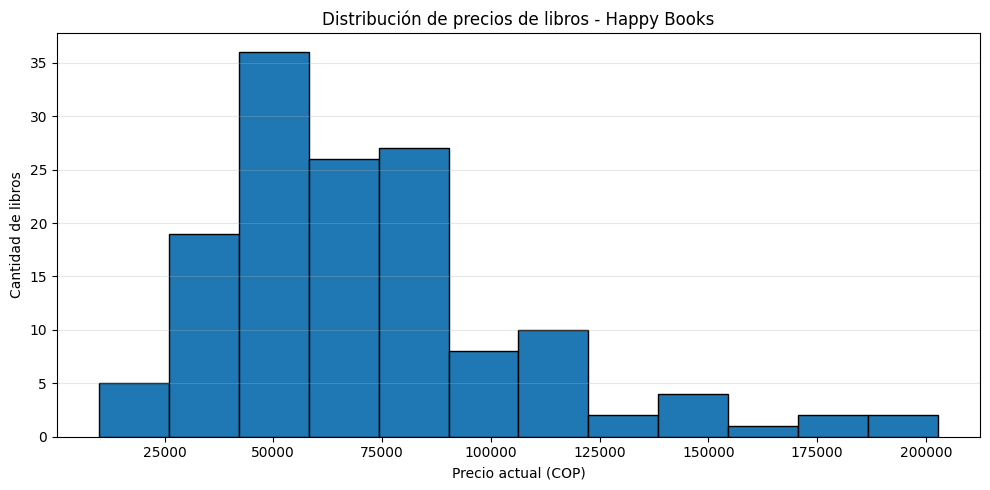

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_libros["precio_actual_cop"],
    bins=12,
    edgecolor="black"
)

plt.title("Distribución de precios de libros - Happy Books")
plt.xlabel("Precio actual (COP)")
plt.ylabel("Cantidad de libros")
plt.ticklabel_format(style="plain", axis="x")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# Exportar los datos extraídos y analizados
archivo_csv = "catalogo_happy_books.csv"

df_libros.to_csv(
    archivo_csv,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado:", archivo_csv)
print("Cantidad de registros:", len(df_libros))
print("Cantidad de columnas:", len(df_libros.columns))
print("Columnas:", df_libros.columns.tolist())

Archivo exportado: catalogo_happy_books.csv
Cantidad de registros: 142
Cantidad de columnas: 7
Columnas: ['titulo', 'autor', 'precio_original_cop', 'precio_actual_cop', 'descuento', 'url', 'descuento_calculado_pct']


In [11]:
from google.colab import files

files.download("catalogo_happy_books.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##probar automatizacion del navegador con selenium

In [12]:
%pip install -q selenium

In [13]:
import selenium

print("Versión de Selenium:", selenium.__version__)
print("Biblioteca importada correctamente.")

Versión de Selenium: 4.51.0
Biblioteca importada correctamente.


In [14]:
!apt-get update -qq
!apt-get install -y chromium chromium-driver

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'chromium-browser' instead of 'chromium'
Note, selecting 'chromium-chromedriver' instead of 'chromium-driver'
chromium-browser is already the newest version (2:1snap1-0ubuntu2).
chromium-chromedriver is already the newest version (2:1snap1-0ubuntu2).
0 upgraded, 0 newly installed, 0 to remove and 17 not upgraded.


In [15]:
%pip install -q webdriver-manager

In [16]:
from webdriver_manager.chrome import ChromeDriverManager

print("webdriver-manager está instalado correctamente.")

webdriver-manager está instalado correctamente.


In [17]:
import os
import shutil

posibles_navegadores = [
    "/usr/bin/google-chrome",
    "/usr/bin/google-chrome-stable",
    "/usr/bin/chromium",
    "/usr/bin/chromium-browser",
    "/opt/google/chrome/chrome"
]

for ruta in posibles_navegadores:
    print(f"{ruta}: {os.path.exists(ruta)}")

print("\nEjecutables encontrados en PATH:")
for nombre in ["google-chrome", "chromium", "chromium-browser"]:
    print(f"{nombre}: {shutil.which(nombre)}")

/usr/bin/google-chrome: True
/usr/bin/google-chrome-stable: True
/usr/bin/chromium: False
/usr/bin/chromium-browser: True
/opt/google/chrome/chrome: True

Ejecutables encontrados en PATH:
google-chrome: /usr/bin/google-chrome
chromium: None
chromium-browser: /usr/bin/chromium-browser


In [18]:
!wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb -O /tmp/google-chrome.deb
!apt-get install -y /tmp/google-chrome.deb

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'google-chrome-stable' instead of '/tmp/google-chrome.deb'
google-chrome-stable is already the newest version (156.0.8078.47-1).
0 upgraded, 0 newly installed, 0 to remove and 17 not upgraded.


In [19]:
!google-chrome --version

Google Chrome 156.0.8078.47 


In [20]:
from selenium import webdriver
from selenium.webdriver.chrome.options import Options

opciones = Options()
opciones.add_argument("--headless=new")
opciones.add_argument("--no-sandbox")
opciones.add_argument("--disable-dev-shm-usage")

driver = webdriver.Chrome(options=opciones)

driver.get("https://happybooks.com.co/")

print("Título:", driver.title)
print("URL:", driver.current_url)
print("Página cargada:", len(driver.page_source), "caracteres")

driver.quit()

Título: Librería Happy Books: Compra libros desde la comodidad de casa
URL: https://happybooks.com.co/
Página cargada: 1160676 caracteres


##Instalacion de Scrapy

In [1]:
%pip install -q scrapy

In [2]:
from twisted.internet import asyncioreactor
asyncioreactor.install()

from twisted.internet import reactor
print("Reactor activo:", reactor.__class__.__module__)

Reactor activo: twisted.internet.asyncioreactor


In [3]:
%%writefile happybooks_spider.py
import scrapy
from scrapy.crawler import CrawlerProcess

class HappyBooksSpider(scrapy.Spider):
    name = "happybooks"
    start_urls = ["https://happybooks.com.co/"]

    def parse(self, response):
        tarjetas = response.css("article.hb-card")
        self.logger.info("Estado HTTP: %s", response.status)
        self.logger.info("Tarjetas encontradas: %s", len(tarjetas))

        for tarjeta in tarjetas:
            titulo = tarjeta.css(".hb-card__title::text").get()
            autor = tarjeta.css(".hb-card__author::text").get()
            precio = tarjeta.css(".hb-card__current-price::text").get()
            enlace = tarjeta.css("a[href*='/products/']::attr(href)").get()

            yield {
                "titulo": titulo.strip() if titulo else None,
                "autor": autor.strip() if autor else None,
                "precio_actual": precio.strip() if precio else None,
                "url": response.urljoin(enlace) if enlace else None
            }

proceso = CrawlerProcess(settings={
    "TWISTED_REACTOR": "twisted.internet.epollreactor.EPollReactor",
    "ROBOTSTXT_OBEY": True,
    "LOG_LEVEL": "INFO",
    "FEEDS": {
        "scrapy_happy_books.json": {
            "format": "json",
            "encoding": "utf8",
            "overwrite": True
        }
    }
})

proceso.crawl(HappyBooksSpider)
proceso.start()

Writing happybooks_spider.py


In [4]:
!python happybooks_spider.py

2026-10-27 03:24:53 [scrapy.utils.log] INFO: Scrapy 2.19.0 started (bot: scrapybot)
2026-10-27 03:24:53 [scrapy.utils.log] INFO: Versions:
{'lxml': '6.1.3',
 'libxml2': '2.14.6',
 'cssselect': '1.6.0',
 'parsel': '1.12.1',
 'w3lib': '2.5.0',
 'Twisted': '26.4.0',
 'Python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]',
 'pyOpenSSL': '26.4.0 (OpenSSL 4.0.3 29 Sep 2026)',
 'cryptography': '50.0.2',
 'Platform': 'Linux-6.6.159+-x86_64-with-glibc2.39'}
2026-10-27 03:24:53 [scrapy.addons] INFO: Enabled addons:
[]
2026-10-27 03:24:53 [scrapy.extensions.telnet] INFO: Telnet Password: 07b14140d81a85b7
2026-10-27 03:24:53 [scrapy.middleware] WARNING: Disabled scrapy.extensions.remote_control.RemoteControl: RemoteControl requires the asyncio support. You can set the REMOTE_CONTROL_ENABLED setting to False to remove this warning.
2026-10-27 03:24:53 [scrapy.middleware] INFO: Enabled extensions:
['scrapy.extensions.corestats.CoreStats',
 'scrapy.extensions.logcount.LogCount',
 'scrapy.exte

In [5]:
import os
import json

archivo = "scrapy_happy_books.json"

print("¿Existe el archivo?:", os.path.exists(archivo))

with open(archivo, "r", encoding="utf-8") as f:
    libros_scrapy = json.load(f)

print("Registros guardados:", len(libros_scrapy))
print("\nPrimer registro:")
print(json.dumps(libros_scrapy[0], ensure_ascii=False, indent=2))

¿Existe el archivo?: True
Registros guardados: 147

Primer registro:
{
  "titulo": "",
  "autor": "",
  "precio_actual": "$59,250",
  "url": "https://happybooks.com.co/products/9789584277954-habitos-atomicos-james-clear"
}


In [6]:
import pandas as pd

df_scrapy = pd.DataFrame(libros_scrapy)

print("Total de registros:", len(df_scrapy))
print("Títulos vacíos:", df_scrapy["titulo"].fillna("").str.strip().eq("").sum())
print("Autores vacíos:", df_scrapy["autor"].fillna("").str.strip().eq("").sum())
print("Precios vacíos:", df_scrapy["precio_actual"].fillna("").str.strip().eq("").sum())
print("URLs vacías:", df_scrapy["url"].fillna("").str.strip().eq("").sum())

display(df_scrapy.head(10))

Total de registros: 147
Títulos vacíos: 147
Autores vacíos: 147
Precios vacíos: 0
URLs vacías: 0


,titulo,autor,precio_actual,url
0,,,"$59,250",https://happybooks.com.co/products/97895842779...
1,,,"$48,750",https://happybooks.com.co/products/como-hacer-...
2,,,"$48,300",https://happybooks.com.co/products/libro-poder...
3,,,"$48,300",https://happybooks.com.co/products/libro-club-...
4,,,"$36,400",https://happybooks.com.co/products/conversacio...
5,,,"$51,750",https://happybooks.com.co/products/97895842996...
6,,,"$54,000",https://happybooks.com.co/products/97895842974...
7,,,"$36,400",https://happybooks.com.co/products/libro-disci...
8,,,"$48,300",https://happybooks.com.co/products/libro-camin...
9,,,"$35,000",https://happybooks.com.co/products/libro-monje...


In [7]:
import requests
from bs4 import BeautifulSoup

url_prueba = libros_scrapy[0]["url"]

respuesta = requests.get(
    url_prueba,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

print("Estado HTTP:", respuesta.status_code)

soup_producto = BeautifulSoup(respuesta.text, "html.parser")

print("\nTítulo de la página:")
print(soup_producto.title.get_text(strip=True) if soup_producto.title else "No encontrado")

print("\nEncabezados de la página:")
for encabezado in soup_producto.select("h1, h2, h3")[:10]:
    print(encabezado.name, "->", encabezado.get_text(" ", strip=True))

Estado HTTP: 200

Título de la página:
Libro Hábitos Atómicos | Happy Books

Encabezados de la página:
h1 -> Libro Hábitos Atómicos
h3 -> Lo que Hace Especial a Este Libro:
h3 -> ¿Por qué Este Libro es Imperdible?
h3 -> Síguenos
h3 -> Infomación
h3 -> Infomación
h3 -> Categorías
h3 -> Categorías
h3 -> Descubre
h3 -> Descubre


In [8]:
print("Título H1:", soup_producto.select_one("h1").get_text(" ", strip=True))

autor_encontrado = soup_producto.find(
    string=lambda texto: texto and "James Clear" in texto
)

print("¿Aparece James Clear en el HTML?:", autor_encontrado is not None)

print("\nMetadatos del producto:")
for etiqueta in soup_producto.select(
    'meta[property="og:title"], meta[property="product:price:amount"], meta[itemprop="author"]'
):
    print(etiqueta.get("property") or etiqueta.get("itemprop"), "->", etiqueta.get("content"))

Título H1: Libro Hábitos Atómicos
¿Aparece James Clear en el HTML?: True

Metadatos del producto:
og:title -> Libro Hábitos Atómicos
product:price:amount -> 59,250
product:price:amount -> COP


In [9]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor
from urllib.parse import urlparse
import re
import json
import time

def extraer_producto_scrapy(registro):
    url = registro.get("url")

    if not url or urlparse(url).netloc != "happybooks.com.co":
        return registro

    try:
        respuesta = requests.get(
            url,
            headers={"User-Agent": "Mozilla/5.0"},
            timeout=20
        )
        respuesta.raise_for_status()

        pagina = BeautifulSoup(respuesta.text, "html.parser")

        h1 = pagina.select_one("h1")
        titulo = h1.get_text(" ", strip=True) if h1 else ""

        # Buscar el autor en los metadatos estructurados.
        autor = ""
        datos = pagina.select_one('script[type="application/ld+json"]')

        if datos:
            try:
                contenido = json.loads(datos.string or datos.get_text())
                elementos = contenido if isinstance(contenido, list) else [contenido]

                for elemento in elementos:
                    if isinstance(elemento, dict):
                        autor_dato = elemento.get("author")
                        if isinstance(autor_dato, dict):
                            autor = autor_dato.get("name", "")
                        elif isinstance(autor_dato, str):
                            autor = autor_dato

                        if autor:
                            break
            except (json.JSONDecodeError, TypeError):
                pass

        # Si no hay autor estructurado, buscarlo en el texto de la página.
        if not autor:
            texto = pagina.get_text(" ", strip=True)
            match = re.search(r"James Clear", texto, re.IGNORECASE)
            if match:
                autor = match.group(0)

        registro["titulo"] = titulo
        registro["autor"] = autor
        return registro

    except Exception as error:
        registro["error"] = str(error)
        return registro

with ThreadPoolExecutor(max_workers=3) as executor:
    libros_corregidos = list(
        executor.map(extraer_producto_scrapy, libros_scrapy)
    )

df_scrapy_corregido = pd.DataFrame(libros_corregidos)

df_scrapy_corregido.to_json(
    "scrapy_happy_books_corregido.json",
    orient="records",
    force_ascii=False,
    indent=2
)

print("Registros procesados:", len(df_scrapy_corregido))
print("Títulos vacíos:", df_scrapy_corregido["titulo"].fillna("").str.strip().eq("").sum())
print("Autores vacíos:", df_scrapy_corregido["autor"].fillna("").str.strip().eq("").sum())
print("Archivo guardado: scrapy_happy_books_corregido.json")

display(df_scrapy_corregido.head(10))

Registros procesados: 147
Títulos vacíos: 87
Autores vacíos: 146
Archivo guardado: scrapy_happy_books_corregido.json


,titulo,autor,precio_actual,url,error
0,Libro Hábitos Atómicos,James Clear,"$59,250",https://happybooks.com.co/products/97895842779...,NaN
1,Libro Cómo hacer que te pasen cosas buenas,,"$48,750",https://happybooks.com.co/products/como-hacer-...,NaN
2,Libro El Poder Del Ahora,,"$48,300",https://happybooks.com.co/products/libro-poder...,NaN
3,Libro El Club De Las 5 De La Mañana,,"$48,300",https://happybooks.com.co/products/libro-club-...,NaN
4,Libro Conversaciones Con Dios I,,"$36,400",https://happybooks.com.co/products/conversacio...,NaN
5,Libro La Psicología Del Dinero,,"$51,750",https://happybooks.com.co/products/97895842996...,NaN
6,Libro Encuentra Tu Persona Vitamina,,"$54,000",https://happybooks.com.co/products/97895842974...,NaN
7,Libro Disciplina Sin Lágrimas,,"$36,400",https://happybooks.com.co/products/libro-disci...,NaN
8,Libro El Camino Del Artista,,"$48,300",https://happybooks.com.co/products/libro-camin...,NaN
9,Libro El Monje Que Vendió Su Ferrari,,"$35,000",https://happybooks.com.co/products/libro-monje...,NaN


In [10]:
import requests
from bs4 import BeautifulSoup

url_prueba = df_scrapy_corregido.loc[1, "url"]

respuesta = requests.get(
    url_prueba,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

soup_autor = BeautifulSoup(respuesta.text, "html.parser")

print("Título:", soup_autor.title.get_text(strip=True))

print("\nElementos que podrían contener el autor:")
for elemento in soup_autor.select(
    '[class*="author"], [class*="autor"], [itemprop="author"], h1'
)[:20]:
    print(
        "Etiqueta:", elemento.name,
        "| Clase:", elemento.get("class"),
        "| Texto:", elemento.get_text(" ", strip=True)[:200]
    )

Título: Libro Cómo hacer que te pasen cosas buenas | Happy Books

Elementos que podrían contener el autor:
Etiqueta: h1 | Clase: ['t4s-product__title'] | Texto: Libro Cómo hacer que te pasen cosas buenas


In [12]:
import re

bloque_producto = soup_autor.select_one("h1.t4s-product__title").parent.parent
texto_producto = bloque_producto.get_text(" ", strip=True)

def extraer_campo(texto, campo, siguientes_campos):
    patron = rf"{campo}\s*:\s*(.*?)(?=\s*(?:{'|'.join(siguientes_campos)})\s*:|$)"
    coincidencia = re.search(patron, texto, re.IGNORECASE)
    return coincidencia.group(1).strip() if coincidencia else None

autor = extraer_campo(
    texto_producto,
    "Autor",
    ["ISBN", "Editorial", "Encuadernación"]
)

isbn = extraer_campo(
    texto_producto,
    "ISBN",
    ["Editorial", "Encuadernación"]
)

editorial = extraer_campo(
    texto_producto,
    "Editorial",
    ["Encuadernación"]
)

print("Título:", soup_autor.select_one("h1.t4s-product__title").get_text(" ", strip=True))
print("Autor:", autor)
print("ISBN:", isbn)
print("Editorial:", editorial)

Título: Libro Cómo hacer que te pasen cosas buenas
Autor: Rojas Estapé, Marian
ISBN: 9786287576179
Editorial: Espasa


In [13]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor
from urllib.parse import urlparse
import re
import time

def extraer_campo(texto, campo, siguientes_campos):
    patron = rf"{campo}\s*:\s*(.*?)(?=\s*(?:{'|'.join(siguientes_campos)})\s*:|$)"
    coincidencia = re.search(patron, texto, re.IGNORECASE)
    return coincidencia.group(1).strip() if coincidencia else None

def extraer_producto(registro):
    resultado = registro.copy()
    url = resultado.get("url")

    if not url or urlparse(url).netloc != "happybooks.com.co":
        return resultado

    try:
        respuesta = requests.get(
            url,
            headers={"User-Agent": "Mozilla/5.0"},
            timeout=20
        )
        respuesta.raise_for_status()

        pagina = BeautifulSoup(respuesta.text, "html.parser")
        h1 = pagina.select_one("h1.t4s-product__title")
        resultado["titulo"] = h1.get_text(" ", strip=True) if h1 else None

        bloque = h1.parent.parent if h1 and h1.parent and h1.parent.parent else pagina
        texto = bloque.get_text(" ", strip=True)

        resultado["autor"] = extraer_campo(
            texto, "Autor", ["ISBN", "Editorial", "Encuadernación"]
        )
        resultado["isbn"] = extraer_campo(
            texto, "ISBN", ["Editorial", "Encuadernación"]
        )
        resultado["editorial"] = extraer_campo(
            texto, "Editorial", ["Encuadernación"]
        )

    except Exception as error:
        resultado["error"] = str(error)

    return resultado

with ThreadPoolExecutor(max_workers=3) as executor:
    registros_finales = list(
        executor.map(extraer_producto, libros_scrapy)
    )

df_scrapy_final = pd.DataFrame(registros_finales)

# Eliminar registros sin URL y duplicados
df_scrapy_final = df_scrapy_final.dropna(subset=["url"])
df_scrapy_final = df_scrapy_final.drop_duplicates(subset=["url"]).reset_index(drop=True)

df_scrapy_final.to_csv(
    "catalogo_happy_books_scrapy.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Registros finales:", len(df_scrapy_final))
print("Títulos vacíos:", df_scrapy_final["titulo"].fillna("").str.strip().eq("").sum())
print("Autores vacíos:", df_scrapy_final["autor"].fillna("").str.strip().eq("").sum())
print("ISBN disponibles:", df_scrapy_final["isbn"].notna().sum())
print("Editoriales disponibles:", df_scrapy_final["editorial"].notna().sum())
print("Archivo guardado: catalogo_happy_books_scrapy.csv")

display(df_scrapy_final.head(10))

Registros finales: 142
Títulos vacíos: 79
Autores vacíos: 81
ISBN disponibles: 61
Editoriales disponibles: 61
Archivo guardado: catalogo_happy_books_scrapy.csv


,titulo,autor,precio_actual,url,isbn,editorial,error
0,Libro Hábitos Atómicos,James Clear,"$59,250",https://happybooks.com.co/products/97895842779...,9789584277954,Paidós Empresa,NaN
1,Libro Cómo hacer que te pasen cosas buenas,"Rojas Estapé, Marian","$48,750",https://happybooks.com.co/products/como-hacer-...,9786287576179,Espasa,NaN
2,Libro El Poder Del Ahora,"Tolle, Eckhart","$48,300",https://happybooks.com.co/products/libro-poder...,9789588618791,Grijalbo,NaN
3,Libro El Club De Las 5 De La Mañana,"Sharma, Robin","$48,300",https://happybooks.com.co/products/libro-club-...,9789585464421,Grijalbo,NaN
4,Libro Conversaciones Con Dios I,"Walsch, Neale Donald","$36,400",https://happybooks.com.co/products/conversacio...,9789585454668,Debolsillo,NaN
5,Libro La Psicología Del Dinero,"Housel, Morgan","$51,750",https://happybooks.com.co/products/97895842996...,9789584299680,Paidós Empresa,NaN
6,Libro Encuentra Tu Persona Vitamina,"Rojas Estapé, Marian","$54,000",https://happybooks.com.co/products/97895842974...,9789584297426,Espasa,NaN
7,Libro Disciplina Sin Lágrimas,"Siegel, Daniel J.; Payne Bryson, Tina","$36,400",https://happybooks.com.co/products/libro-disci...,9789585672345,B De Bolsillo,NaN
8,Libro El Camino Del Artista,"Cameron, Julia","$48,300",https://happybooks.com.co/products/libro-camin...,9789585549142,Aguilar,NaN
9,Libro El Monje Que Vendió Su Ferrari,"Sharma, Robin","$35,000",https://happybooks.com.co/products/libro-monje...,9789586392518,Debolsillo,NaN


##Mostar Registros incompletos

In [14]:
incompletos = df_scrapy_final[
    df_scrapy_final["titulo"].isna()
    | df_scrapy_final["titulo"].fillna("").str.strip().eq("")
    | df_scrapy_final["autor"].isna()
    | df_scrapy_final["autor"].fillna("").str.strip().eq("")
]

print("Registros con título o autor incompleto:", len(incompletos))

display(
    incompletos[["titulo", "autor", "precio_actual", "url"]].head(15)
)

Registros con título o autor incompleto: 81


,titulo,autor,precio_actual,url
61,Verity. La sombra de un engaño (Edición tie-in),,"$41,250",https://happybooks.com.co/products/libro-verit...
62,Villanos. La Bestia,,"$79,000",https://happybooks.com.co/products/libro-villa...
63,,,"$79,000",https://happybooks.com.co/products/libro-villa...
64,,,"$79,000",https://happybooks.com.co/products/libro-villa...
65,,,"$79,000",https://happybooks.com.co/products/libro-villa...
66,,,"$79,000",https://happybooks.com.co/products/libro-50-re...
67,,,"$79,000",https://happybooks.com.co/products/libro-el-ci...
68,,,"$139,000",https://happybooks.com.co/products/libro-las-c...
69,,,"$59,000",https://happybooks.com.co/products/libro-maria...
70,,,"$49,000",https://happybooks.com.co/products/libro-maldi...


In [16]:
fila = df_scrapy_final.iloc[63]
url_prueba = fila["url"]

print("URL:", url_prueba)

respuesta = requests.get(
    url_prueba,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

print("Estado HTTP:", respuesta.status_code)

pagina_prueba = BeautifulSoup(respuesta.text, "html.parser")

print("Título HTML:", pagina_prueba.title.get_text(" ", strip=True)
      if pagina_prueba.title else "No encontrado")

print("H1:", pagina_prueba.select_one("h1").get_text(" ", strip=True)
      if pagina_prueba.select_one("h1") else "No encontrado")

print("\nTexto del bloque de producto:")
h1 = pagina_prueba.select_one("h1.t4s-product__title")

if h1:
    bloque = h1.parent.parent
    print(bloque.get_text(" ", strip=True)[:1500])
else:
    print("No se encontró el encabezado esperado.")


URL: https://happybooks.com.co/products/libro-villanos-la-emperatriz-del-mal-disney-9786287575752
Estado HTTP: 200
Título HTML: Villanos, La emperatriz del mal | Happy Books
H1: Villanos. La emperatriz del mal

Texto del bloque de producto:
Villanos. La emperatriz del mal $79,000 Agregar al wishlist Agregar al carrito Villanos, La emperatriz del mal Antes de maldecir a Aurora,... Leer más Autor: Disney ISBN: 9786287575752 Editorial: Crossbooks Encuadernación: Tapa dura ¿TIENES ALGUNA PREGUNTA?


In [17]:
import re
import requests
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor

def extraer_campo_producto(texto, campo, siguientes):
    patron = rf"{campo}\s*:\s*(.*?)(?=\s*(?:{'|'.join(siguientes)})\s*:|$)"
    coincidencia = re.search(patron, texto, re.IGNORECASE)
    return coincidencia.group(1).strip() if coincidencia else None

def corregir_fila(fila):
    resultado = fila.copy()

    if (
        str(resultado.get("titulo") or "").strip()
        and str(resultado.get("autor") or "").strip()
        and str(resultado.get("isbn") or "").strip()
        and str(resultado.get("editorial") or "").strip()
    ):
        return resultado

    url = resultado.get("url")

    try:
        respuesta = requests.get(
            url,
            headers={"User-Agent": "Mozilla/5.0"},
            timeout=20
        )
        respuesta.raise_for_status()

        pagina = BeautifulSoup(respuesta.text, "html.parser")
        h1 = pagina.select_one("h1.t4s-product__title")
        if h1:
            resultado["titulo"] = h1.get_text(" ", strip=True)

            bloque = h1.parent.parent
            texto = bloque.get_text(" ", strip=True)

            resultado["autor"] = (
                extraer_campo_producto(
                    texto, "Autor", ["ISBN", "Editorial", "Encuadernación"]
                )
                or resultado.get("autor")
            )

            resultado["isbn"] = (
                extraer_campo_producto(
                    texto, "ISBN", ["Editorial", "Encuadernación"]
                )
                or resultado.get("isbn")
            )

            resultado["editorial"] = (
                extraer_campo_producto(
                    texto, "Editorial", ["Encuadernación"]
                )
                or resultado.get("editorial")
            )

    except Exception as error:
        resultado["error"] = str(error)

    return resultado

indices_incompletos = df_scrapy_final.index[
    df_scrapy_final["titulo"].fillna("").str.strip().eq("")
    | df_scrapy_final["autor"].fillna("").str.strip().eq("")
    | df_scrapy_final["isbn"].fillna("").str.strip().eq("")
    | df_scrapy_final["editorial"].fillna("").str.strip().eq("")
]

filas = [df_scrapy_final.loc[i].copy() for i in indices_incompletos]

with ThreadPoolExecutor(max_workers=3) as executor:
    corregidas = list(executor.map(corregir_fila, filas))

for i, fila_corregida in zip(indices_incompletos, corregidas):
    for columna, valor in fila_corregida.items():
        df_scrapy_final.loc[i, columna] = valor

df_scrapy_final.to_csv(
    "catalogo_happy_books_scrapy.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Registros:", len(df_scrapy_final))
print("Títulos vacíos:", df_scrapy_final["titulo"].fillna("").str.strip().eq("").sum())
print("Autores vacíos:", df_scrapy_final["autor"].fillna("").str.strip().eq("").sum())
print("ISBN disponibles:", df_scrapy_final["isbn"].fillna("").str.strip().ne("").sum())
print("Editoriales disponibles:", df_scrapy_final["editorial"].fillna("").str.strip().ne("").sum())

Registros: 142
Títulos vacíos: 20
Autores vacíos: 20
ISBN disponibles: 122
Editoriales disponibles: 120


In [18]:
pendientes = df_scrapy_final[
    df_scrapy_final["titulo"].fillna("").str.strip().eq("")
    | df_scrapy_final["autor"].fillna("").str.strip().eq("")
]

print("Registros pendientes:", len(pendientes))

display(
    pendientes[
        ["titulo", "autor", "isbn", "editorial", "url", "error"]
    ]
)


Registros pendientes: 20


,titulo,autor,isbn,editorial,url,error
121,,,NaN,NaN,https://happybooks.com.co/products/libro-lo-qu...,429 Client Error: Too Many Requests for url: h...
122,,,NaN,NaN,https://happybooks.com.co/products/libro-tu-ki...,429 Client Error: Too Many Requests for url: h...
123,,,NaN,NaN,https://happybooks.com.co/products/happy-marks...,429 Client Error: Too Many Requests for url: h...
125,,,NaN,NaN,https://happybooks.com.co/products/libreta-pan...,429 Client Error: Too Many Requests for url: h...
126,,,NaN,NaN,https://happybooks.com.co/products/libreta-pal...,429 Client Error: Too Many Requests for url: h...
127,,,NaN,NaN,https://happybooks.com.co/products/libreta-est...,429 Client Error: Too Many Requests for url: h...
128,,,NaN,NaN,https://happybooks.com.co/products/calendario-...,429 Client Error: Too Many Requests for url: h...
129,,,NaN,NaN,https://happybooks.com.co/products/libro-el-mu...,429 Client Error: Too Many Requests for url: h...
130,,,NaN,NaN,https://happybooks.com.co/products/libro-astro...,429 Client Error: Too Many Requests for url: h...
131,,,NaN,NaN,https://happybooks.com.co/products/libro-tarot...,429 Client Error: Too Many Requests for url: h...


In [19]:
df_scrapy_final.to_csv(
    "catalogo_happy_books_respaldo.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Respaldo guardado correctamente.")
print("Registros conservados:", len(df_scrapy_final))
print(
    "Registros con error 429:",
    df_scrapy_final["error"]
    .fillna("")
    .str.contains("429", regex=False)
    .sum()
)

Respaldo guardado correctamente.
Registros conservados: 142
Registros con error 429: 81


In [20]:
import pandas as pd

print("RESUMEN DEL CATÁLOGO")
print("-" * 35)
print("Total de registros:", len(df_scrapy_final))
print(
    "URL únicas:",
    df_scrapy_final["url"].nunique()
)
print(
    "Títulos disponibles:",
    df_scrapy_final["titulo"].fillna("").str.strip().ne("").sum()
)
print(
    "Autores disponibles:",
    df_scrapy_final["autor"].fillna("").str.strip().ne("").sum()
)
print(
    "ISBN disponibles:",
    df_scrapy_final["isbn"].fillna("").str.strip().ne("").sum()
)
print(
    "Editoriales disponibles:",
    df_scrapy_final["editorial"].fillna("").str.strip().ne("").sum()
)
print(
    "Registros con error 429:",
    df_scrapy_final["error"].fillna("").str.contains("429", regex=False).sum()
)

RESUMEN DEL CATÁLOGO
-----------------------------------
Total de registros: 142
URL únicas: 142
Títulos disponibles: 122
Autores disponibles: 122
ISBN disponibles: 122
Editoriales disponibles: 120
Registros con error 429: 81
